# Matplotlib for Visualization (Workbook)

### Credits
Code and text by Antonio C. Briza (acbriza at gmail dot com) [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

Additional code and text from
- *Python for Data Analysis*, 2nd Edition (Chapter 9) by Wes McKinney
    - Text are annotated by `[PDA]`; Code are annotated by `#PDA`
- [Anatomy of Matplotlib](https://github.com/matplotlib/AnatomyOfMatplotlib) Part 2 by Benjamin Root; Copyright: CC BY 3.0
    - Text are annotated by `[AOM]`; code are annotated by `#AOM`
- [matplotlib's pyplot Tutorial](https://matplotlib.org/users/pyplot_tutorial.html) from Matplotlib's documentation.
    - Text are annotated by `[MPT]`; code are annotated by `#MPT`
- [Scipy Lecture Notes' Matplotlib Tutorial](http://www.scipy-lectures.org/intro/matplotlib/index.html) by Nicolas Rougier, Mike Müller and Gaël Varoquaux.
    - Text are annotated by `[SLN]`; code are annotated by `#SLN`

Inline comments on lifted materials:
- Text are annotated by `[あ]`; code are annotated by `#あ`

Last modified: March 20, 2018.<br>
Please report errors to acbriza at gmail dot com

<a id='contents'></a>

# TABLE OF CONTENTS

<a id='contents'></a>
[1 Introduction](#lesson1)<br>
[2 Function Arguments](#lesson2)<br>
[3 Anatomy of a "Plot"](#lesson3)<br>

[4 OOP-Style Plotting](#lesson4)<br>
[4.1 Figures and Subplots](#lesson41)<br>
[4.2 Plot colors, styles and markers](#lesson42)<br>
[4.3 Setting Limits](#lesson43)<br>
[4.4 Title, axis labels, ticks and ticklabels](#lesson43)<br>
[4.5 Legends](#lesson45)<br>
[4.6 Annotations](#lesson46)<br>
[4.7 Log Scale and Other Plot Types](#lesson47)<br>
[4.8 Saving Plots](#lesson48)<br>

[5 Commands-Style Plotting with `pyplot`](#lesson5)<br>
[6 Plotting with Pandas and Seaborn](#lesson6)<br>
[7 References](#lesson7)<br>

<a id='lesson1'></a>

# 1. Introduction

Visualization or plotting is important in the data analysis process for the following reasons:
- Plots give an analyst an initial feel of how the data looks like. They answer the following questions: What initial relationships could be observed among the variables? Are there missing data? Are there outliers? All of these could provide an insight if the initially-gathered data still need transformation and which models may be more suitable.
- Plots could show in a succint and powerful way the value of an analysis in a way that may be more effective than words.

> `Matplotlib` is a library for producing publication-quality figures. `mpl`(alias for `Matplotlib`) -- much like Python itself -- gives the developer complete control over the appearance of their plots, while still being very usable through a powerful defaults system.  
>
>`Matplotlib` has multiple `backends`. The backends allow `mpl` to be used on a variety of platforms with a variety of GUI (Graphical User Interface) toolkits.

[AOM]

Some types of backend are for interactive plotting, and some are for plotting directly to image files. When you import `matplotlib` in Jupyter, the default backend is `inline`. This backend  displays the plots in the notebook itself.

For this lecture, we will only be working with the `inline` backend. You can explicitly indicate that you want to use the `inline` backend by running the following magic command:
```python
%matplotlib inline
```

Let's go ahead and import `NumPy`, `pandas` and `matplotlib`'s `pyplot` and set `matplotlib`'s backend to `inline`:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

[TABLE OF CONTENTS](#contents)

<a id='lesson2'></a>
# 2. Function Arguments

Before we proceed with the discussion on `matplotlib`, it is important to review and understand well how function arguments work in python.

## 2.1 Positional Arguments

Arguments are matched to parameters in the order that they are passed.

In [ ]:
def func_pos(a, b, c):
    print('a={}, b={}, c={}'.format(a, b, c))
    print('Done!\n')

func_pos(1, 2, 3)
func_pos(3, 2, 1)

a=1, b=2, c=3
Done!

a=3, b=2, c=1
Done!



The number of parameters has to match the number of arguments.

In [ ]:
try:
    func_pos(3, 2)
except TypeError as error:
    print('Error:', error)

Error: func_pos() missing 1 required positional argument: 'c'


## 2.2 Default Parameter Values

Function parameters can have default values, such that the function can be called without providing arguments for some or all of these parameters.  Again, the arguments are matched to the parameters in the order that they were passed.

In [ ]:
def func_def(a=1, b=2, c=3):
    print('a={}, b={}, c={}'.format(a, b, c))
    print('Done!\n')

func_def()        # No arguments passed; all parameters take default values
func_def(4)       # 1 argument passed, it is matched to the 1st parameter
func_def(4, 5)    # 2 arguments passed, it is matched to the 1st & 2nd parameters, in that order
func_def(4, 5, 6) # 3 arguments passed, it is matched to the 1st, 2nd & 3rd parameters, in that order

a=1, b=2, c=3
Done!

a=4, b=2, c=3
Done!

a=4, b=5, c=3
Done!

a=4, b=5, c=6
Done!



## 2.3 Keyword Arguments

Arguments can also be passed to functions by specifying the name of the parameter that it matches. This is called **keyword argument** or **named argument**.  When calling a function solely with keyword arguments, the order does not matter, since python matches the parameters to the arguments by name.

In [ ]:
func_def(b=5, c=6, a=4)
func_def(c=6, a=4, b=5)

a=4, b=5, c=6
Done!

a=4, b=5, c=6
Done!



## 2.4 Combining Positional and Keyword Arguments

Positional and keyword arguments could be mixed so long as the positional arguments come first.

In [ ]:
func_def(4, b=5)
func_def(4, b=5, c=6)
func_def(4, 5, c=6)

a=4, b=5, c=3
Done!

a=4, b=5, c=6
Done!

a=4, b=5, c=6
Done!



In [ ]:
# This code will produce a syntax error
func_def(b=6, 4)

SyntaxError: positional argument follows keyword argument (844782525.py, line 2)

## 2.5 \*args and **kwargs as Function parameters

You could often find parameters listed as `*args` `**kwargs` in some python documentation, such as that of `plt.plot()`:

In [ ]:
help(plt.plot)

Help on function plot in module matplotlib.pyplot:

plot(
    *args: 'float | ArrayLike | str',
    scalex: 'bool' = True,
    scaley: 'bool' = True,
    data=None,
    **kwargs
) -> 'list[Line2D]'
    Plot y versus x as lines and/or markers.

    Call signatures::

        plot([x], y, [fmt], *, data=None, **kwargs)
        plot([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

    The coordinates of the points or line nodes are given by *x*, *y*.

    The optional parameter *fmt* is a convenient way for defining basic
    formatting like color, marker and linestyle. It's a shortcut string
    notation described in the *Notes* section below.

    >>> plot(x, y)        # plot x and y using default line style and color
    >>> plot(x, y, 'bo')  # plot x and y using blue circle markers
    >>> plot(y)           # plot y using x as index array 0..N-1
    >>> plot(y, 'r+')     # ditto, but with red plusses

    You can use `.Line2D` properties as keyword arguments for more
    control on th

`**args` allows you to pass a variable-length of unnamed arguments to a function.  Python creates a
tuple from the arguments that are passed. This tuple could then be used inside function in a manner similar to the illustration given below:

In [ ]:
def func_args(*args):
    print(type(args))
    for i, item in enumerate(args):
        print('argument {}: {}'.format(i, item))
    print('Done!\n')

func_args()
func_args(1.)
func_args(1., 2.)

<class 'tuple'>
Done!

<class 'tuple'>
argument 0: 1.0
Done!

<class 'tuple'>
argument 0: 1.0
argument 1: 2.0
Done!



`**kwargs` allows you to pass several keyword arguments to a function in the format `keyword=value`.  Python creates a
dictionary from the keyword arguments that are passed. This dictionary could then be used inside function in a manner similar to the illustration given below:

In [ ]:
def func1(**kwargs):
    print(type(kwargs))
    for key, value in kwargs.items():
        print('{}:{}'.format(key, value))
    print('Done!\n')

func1(arg1=1, arg2="two", arg3=[3])
func1(arg1=1)
func1()

<class 'dict'>
arg1:1
arg2:two
arg3:[3]
Done!

<class 'dict'>
arg1:1
Done!

<class 'dict'>
Done!



Keep in mind that learning how to use many of the tools in `matplotlib` (in fact, in many python packages) requires a good grasp of how function arguments work in python.  

Now let's get into `matplotlib` itself.

[TABLE OF CONTENTS](#contents)

<a id='lesson3'></a>

# 3. Anatomy of a "Plot"

*Most of this section comes is lifted from [AOM]. Text directly lifted from this source are indented in a quote block, while code are annotated with a `#AOM` at the last line of the code cell.*

>People use "plot" to mean many different things.  Here, we'll be using a consistent terminology (mirrored by the names of the underlying classes, etc):

<img src="images/figure_axes_axis_labeled.png" width="400" >

>The ``Figure`` is the top-level container in this hierarchy.  It is the overall window/page that everything is drawn on.  You can have multiple independent figures and ``Figure``s can contain multiple ``Axes``.
>
>Most plotting ocurs on an ``Axes``.  The axes is effectively the area that we plot data on and any ticks/labels/etc associated with it.  Usually we'll set up an Axes with a call to ``subplot()`` (which places Axes on a regular grid), so in most cases,
**``Axes`` and ``Subplot`` are synonymous**.
>
>Each ``Axes`` has an ``XAxis`` and a ``YAxis``.  These contain the ticks, tick locations, labels, etc.  

## 3.1 Figure

>Typically, you'll set up a `Figure`, and then add an `Axes` to it.
>
>All plotting is done with respect to an [`Axes`](http://matplotlib.org/api/axes_api.html#matplotlib.axes.Axes). An *Axes* is made up of [`Axis`](http://matplotlib.org/api/axis_api.html#matplotlib.axis.Axis) objects and many other things. An *Axes* object must belong to a *Figure* (and only one *Figure*). Most commands you will ever issue will be with respect to this *Axes* object.
>
>You can use `fig.add_axes`, but in most cases, you'll find that adding a `subplot` will fit your needs perfectly. (Again a `subplot` is just an `axes` on a grid system.)

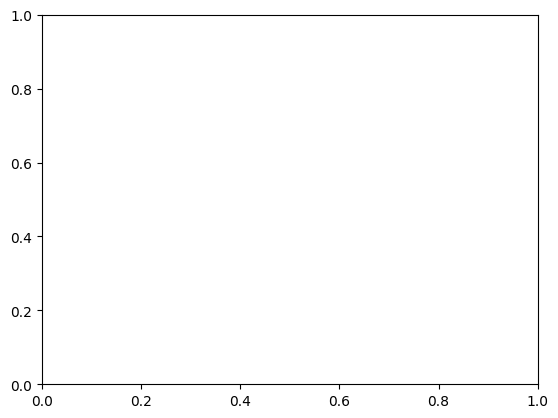

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111) # We'll explain the "111" later. Basically, 1 row and 1 column. #あ and accessing the 1st Axis
#AOM

You can control the size of the figure through the figsize argument, which expects a tuple of (width, height) in inches.

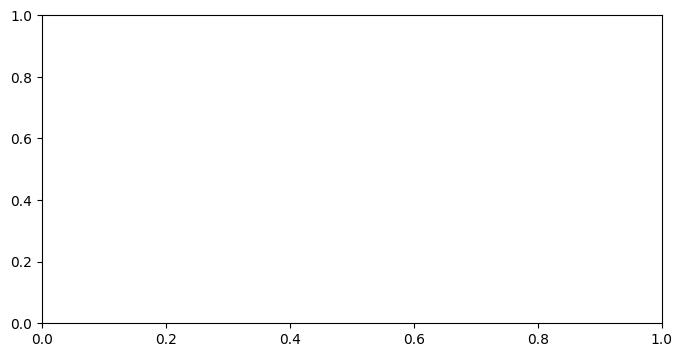

In [ ]:
fig = plt.figure(figsize=(8,4))  #あ set figure size
ax = fig.add_subplot(111)
#AOM

##  3.2 Axes
> Most plotting ocurs on an ``Axes``.  The axes is effectively the area that we plot data on and any ticks/labels/etc associated with it.  Usually we'll set up an Axes with a call to ``subplot()`` (which places Axes on a regular grid), so in most cases, **``Axes`` and ``Subplot`` are synonymous**.

[(0.5, 4.5),
 (-2.0, 8.0),
 Text(0.5, 1.0, 'An Example Axes'),
 Text(0, 0.5, 'Y-Axis'),
 Text(0.5, 0, 'X-Axis')]

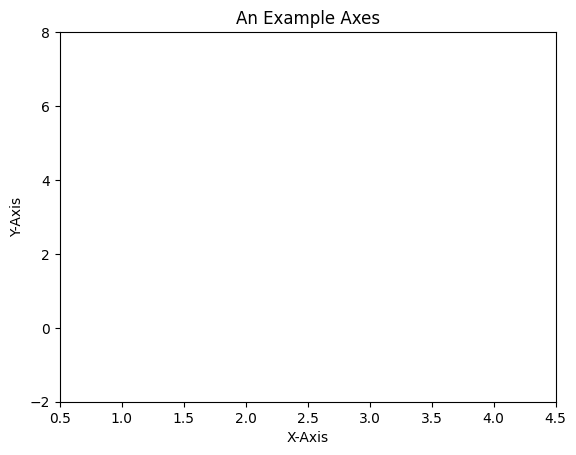

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.set(xlim=[0.5, 4.5], ylim=[-2, 8], title='An Example Axes',
       ylabel='Y-Axis', xlabel='X-Axis')
#AOM

>Notice the call to ``set``. Matplotlib's objects typically have lots of "explicit setters" -- in other words, functions that start with ``set_<something>`` and control a particular option.
>
>To demonstrate this (and as an example of IPython's tab-completion), try typing `ax.set_` in a code cell, then hit the `<Tab>` key.  You'll see a long list of `Axes` methods that start with `set`.

In [ ]:
ax.set

AttributeError: 'Axes' object has no attribute 'set_'

>For example, we could have written the third line above as:

Text(0.5, 0, 'X-Axis')

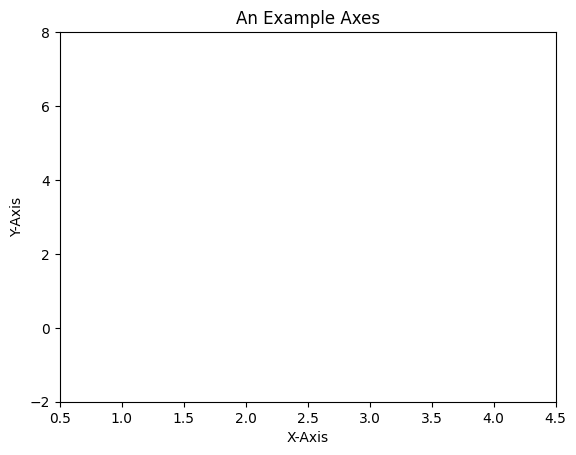

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
#---------------------------------------------------------
ax.set_xlim([0.5, 4.5])
ax.set_ylim([-2, 8])
ax.set_title('An Example Axes')
ax.set_ylabel('Y-Axis')
ax.set_xlabel('X-Axis')
#---------------------------------------------------------
#AOM

>Clearly this can get repetitive quickly.  Therefore, Matplotlib's `set()` method can be very handy.  It takes each Keyword Argument (`kwarg`) you pass it and tries to call the corresponding "setter".  
>
>For example, `object.set(arg='value')` would call `object.set_arg('value')`, where `arg` is a Keyword Argument encoding a certain option.  
>
>Note that the `set()` method doesn't just apply to `Axes`; it applies to more-or-less all matplotlib objects.
>
>However, there are cases where you'll want to use things like `ax.set_xlabel('Some Label', size=25)` to control other options for a particular function.

### Side Notes
[あ]

Let's take a closer look at `fig` and `ax`

In [ ]:
type(fig)

matplotlib.figure.Figure

In [ ]:
type(ax)

matplotlib.axes._axes.Axes

Observe the following:
- `fig`
   - a `Figure` object
- `ax`
    - an `Axes` object added to `fig`
- `ax.set()`
    - a `method` in the `Axes` object named `ax`

Also notice that in the 2 plots above, Jupyter notebook also printed a list of items. These are the return values of the last statement. We'll talk about this later. To suppress displaying that text output, you could put a semicolon (`;`) at the end of the statement, as in the code below.

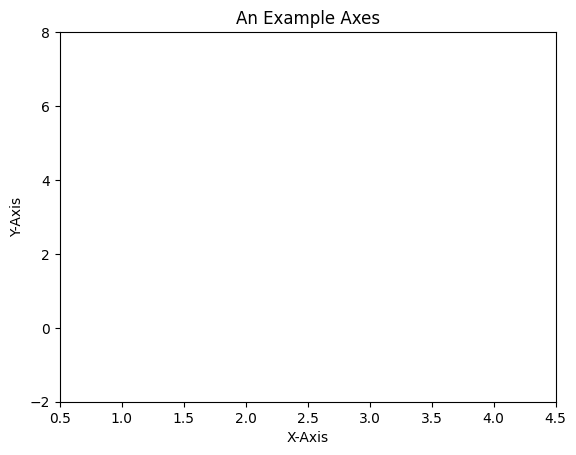

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.set(xlim=[0.5, 4.5], ylim=[-2, 8], title='An Example Axes',
       ylabel='Y-Axis', xlabel='X-Axis'); #あ add semicolon to suppress output to notebook
#AOM

## 3.3 Axis

>Each ``Axes`` has an ``XAxis`` and a ``YAxis``.  These contain the ticks, tick locations, labels, etc.  

In [ ]:
ax.xaxis.get_label()  #あ Access the X-Axis label

Text(0.5, 24.0, 'X-Axis')

## 3.4 Artists

>Basically everything you can see on the figure is an `Artist` (even the `Figure`, `Axes`, and `Axis` objects). This includes `Text` objects, `Line2D` objects... When the figure is rendered, all of the artists are drawn to the canvas.

## 3.5 Anatomy of a Figure

Below is a more detailed illustration of the [Anatomy of a Figure](https://matplotlib.org/2.0.2/faq/usage_faq.html#parts-of-a-figure) from matplotlib's documentation.



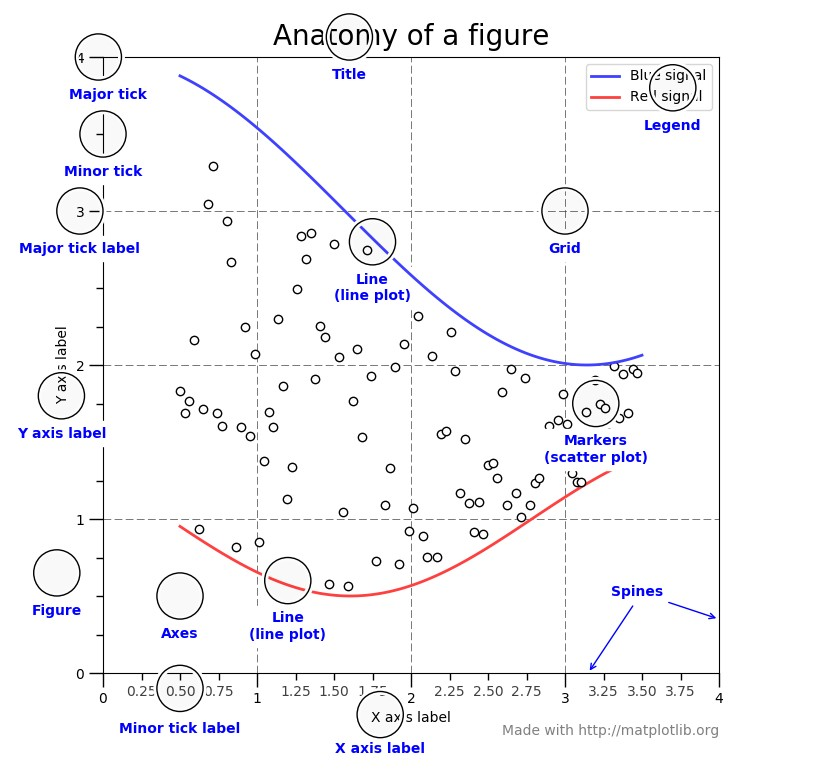

In [ ]:
from IPython.display import Image
Image('Datasets/images/Anatomy.jpg')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes

/content/drive/MyDrive/ColabNotebooks/ICT110-AppDev/ColabNotes


In [ ]:
ls

'10 Supervised_Machine_Learning_Regression.ipynb'
 boston_house_price_project.ipynb
 boston_model_card.json
 boston_model.joblib
 build_datasets.ipynb
 build_worldbank_who_dataset.py
 Datasets/
 gdp_na_dropped.xlsx
'Matplotlib for Visualization (Workbook).ipynb'
 Models/
'NumPy for Numerical Computing (Lecture).ipynb'
'Pandas for Data Manipulation and Analysis-1 .ipynb'
'Pandas for Data Manipulation and Analysis -2 .ipynb'
 PythonCodes/
 WorldBank_WHO_Country_Dataset_2015.csv


[TABLE OF CONTENTS](#contents)

<a id='lesson4'></a>
# 4. OOP-Style Plotting  

*This section follows the outline in Chapter 9 of **Python for Data Analysis, 2nd Edition** by Wes McKinney. Code directly lifted from this source is annotated by `#PDA` at the last line of the code cell.*

There are two ways of plotting in `matplotlib`. The first uses `matplotlib` objects in an Object Oriented Programming (OOP) fashion. The second uses command-style functions.  The first method is more explicit and flexible and could thus be more laborious. The second is shorter (and many times cleaner). However, it is less flexible and may not be able to handle more detailed plotting needs. In this section, we will take a look at the OOP method of creating plots.

<a id='lesson41'></a>
## 4.1 Figures and Subplots

You create a `subplot` (or `axes`) in a figure by calling `add_subplot()` method of a figure object. To create one plot, a call to  `add_subplot(1, 1, 1)` would suffice.

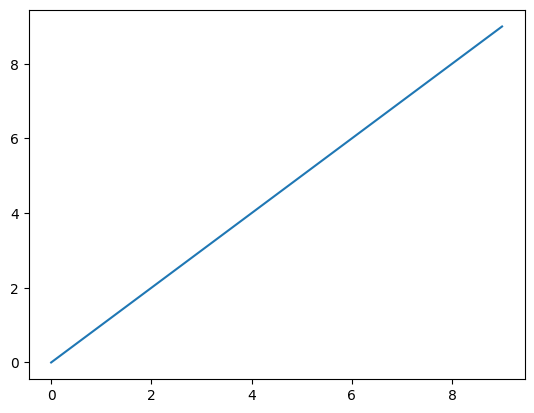

In [ ]:
d1 = np.arange(10) # the data
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1) # Create an axes
ax.plot(d1);

The call `add_subplot(1, 1, 1)` created an `axes` object in a 1x1 grid of axes objects. In general, the function call `add_subplot(nrows, ncols, index)` creates a subplot (or an `axes` object) for `index` in an axes grid containing `nrows` rows and `ncols` columns. **`index` start at `1`** and goes left to right on columns, then top to bottom on rows.

Let's create a 2x2 multiple axes/subplots and plot on index 1

In [ ]:
np.random.seed(2121)
d2 = np.random.randn(10)*10
d3 = d1**2
d4 = np.sin(d1)

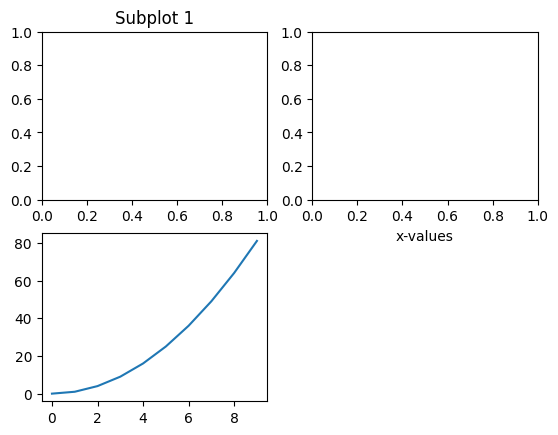

In [ ]:
fig = plt.figure()
ax1 = fig.add_subplot(2, 2, 1) # Return 1st axes of a 2x2 axes grid
ax2 = fig.add_subplot(2, 2, 2) # Return 2nd axes of a 2x2 axes grid
ax3 = fig.add_subplot(2, 2, 3) # Return 3rd axes of a 2x2 axes grid

ax1.set_title('Subplot 1'); # Set title on axes index 1
ax2.set_xlabel('x-values'); # Set x-axis label on axes index 2
ax3.plot(d3);                # Do a line plot on axes index 3

#### Notes
- With the `inline` backend, figures are shown automatically in Jupyter, even if you don't call `plt.show()` (which is required in other backends)
- In Jupyter notebook, plots are evaluated per cell. Thus, all commands that you want to do for a specific plot have to be contained in the same cell.

### plt.subplots() function

The method above directly uses `matplotlib` objects in OOP-style. A lot of things that you can do with the `matplotlib` objects could also be done with shorter, and sometimes cleaner code with `pyplot` command-style functions (more on this in Lesson 4). One example of such convenience function in `pyplot` is the **`subplots()`** function that creates a grid of subplots.

Call signature:
```python    
    subplots(nrows=1, ncols=1, sharex=False, sharey=False)
```
Return values:
- a `figure` object and an array of axes objects
- an `axes` object or an array of Axes objects, depending on the call

In [ ]:
help(plt.subplots)

Help on function subplots in module matplotlib.pyplot:

subplots(
    nrows: 'int' = 1,
    ncols: 'int' = 1,
    *,
    sharex: "bool | Literal['none', 'all', 'row', 'col']" = False,
    sharey: "bool | Literal['none', 'all', 'row', 'col']" = False,
    squeeze: 'bool' = True,
    width_ratios: 'Sequence[float] | None' = None,
    height_ratios: 'Sequence[float] | None' = None,
    subplot_kw: 'dict[str, Any] | None' = None,
    gridspec_kw: 'dict[str, Any] | None' = None,
    **fig_kw
) -> 'tuple[Figure, Any]'
    Create a figure and a set of subplots.

    This utility wrapper makes it convenient to create common layouts of
    subplots, including the enclosing figure object, in a single call.

    Parameters
    ----------
    nrows, ncols : int, default: 1
        Number of rows/columns of the subplot grid.

    sharex, sharey : bool or {'none', 'all', 'row', 'col'}, default: False
        Controls sharing of properties among x (*sharex*) or y (*sharey*)
        axes:

        - T

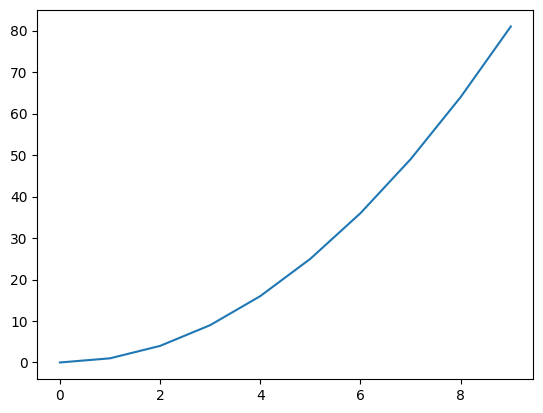

In [ ]:
# create a figure with 1 axes
fig, ax = plt.subplots()
ax.plot(d3);

array([[<Axes: >, <Axes: >, <Axes: >],
       [<Axes: >, <Axes: >, <Axes: >]], dtype=object)

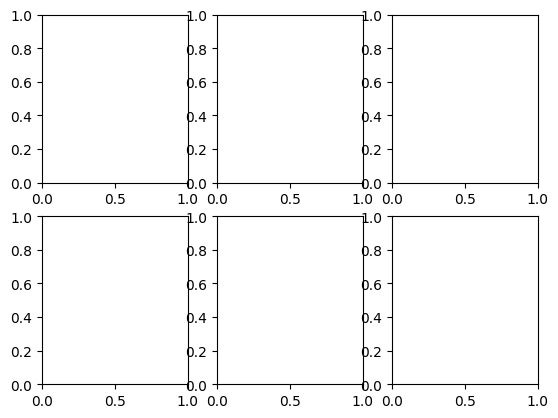

In [ ]:
# create a figure with 2x3 axes/subplots grid
fig, axes = plt.subplots(2, 3)
axes

The useful thing about axes grid is that it could be indexed using the `[row, col]` notation. Upper left subplot is indexed `[0, 0]`

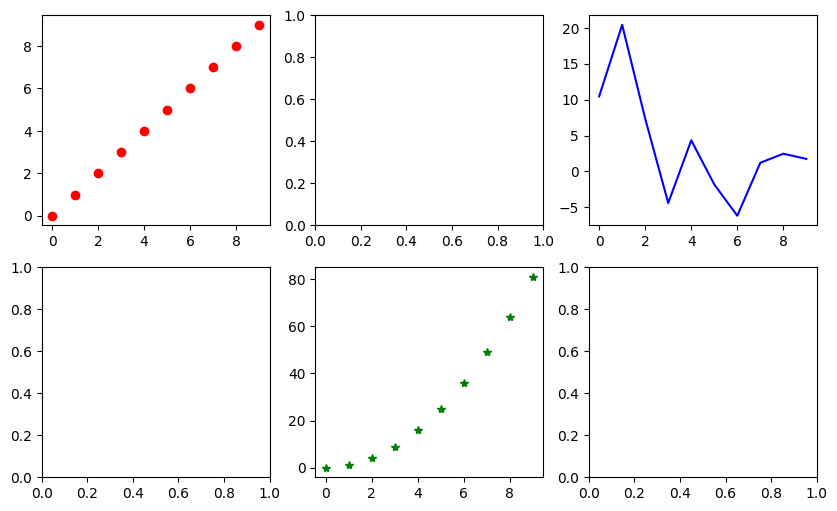

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(10,6))
axes[0,0].plot(d1, 'ro') #plot with red circle markers
axes[0,2].plot(d2, 'b-') #plot with blue line
axes[1,1].plot(d3, 'g*') #plot with green star markers

A useful parameter for `subplots()` is `sharex` and `sharey` for sharing the X-Axis and Y-Axis ticks respectively

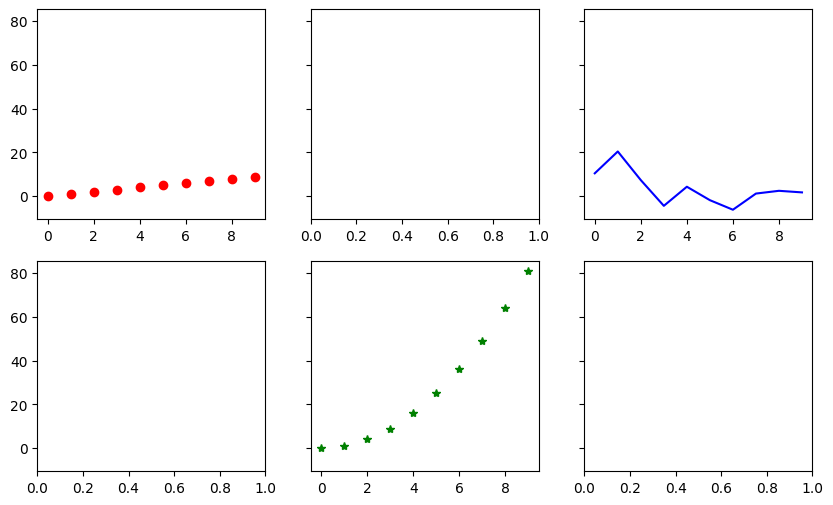

In [ ]:
fig, axes = plt.subplots(2, 3, sharey=True, figsize=(10,6))
axes[0,0].plot(d1, 'ro') #plot with red circle markers
axes[0,2].plot(d2, 'b-') #plot with blue line
axes[1,1].plot(d3, 'g*') #plot with green star markers

[TABLE OF CONTENTS](#contents)

<a id='lesson42'></a>
## 4.2 Plot colors, styles and markers

Plotting with lines and markers is done with `plt.plot().`

Call Signature
```python
plot(*args, scalex=True, scaley=True, data=None, **kwargs)
```

Sample Calls
```python
    plot(x, y)        # plot x and y using default line style and color
    plot(x, y, 'bo')  # plot x and y using blue circle markers
    plot(y)           # plot y using x as index array 0..N-1
    plot(y, 'r+')     # ditto, but with red plusses    
```

`plt.plot()` accepts an optional string argument for specifying the color, line style, and marker of the plot. String codes for the color, style and marker are concatenated to specify the appearance of the plot.

### Color Codes
    character   color
    ==========  ========
    'b'         blue
    'g'         green
    'r'         red
    'c'         cyan
    'm'         magenta
    'y'         yellow
    'k'         black
    'w'         white

### Line Style Codes
    character           description
    =========           ====================
    ``'-'``             solid line style
    ``'--'``            dashed line style
    ``'-.'``            dash-dot line style
    ``':'``             dotted line style

### Marker Codes (subset)
    character           description
    =========           ====================
    ``'o'``             circle marker
    ``'*'``             star marker
    ``'+'``             plus marker
    ``'x'``             x marker
    ``'v'``             triangle_down marker
    ``'^'``             triangle_up marker
    ``'.'``             point marker    

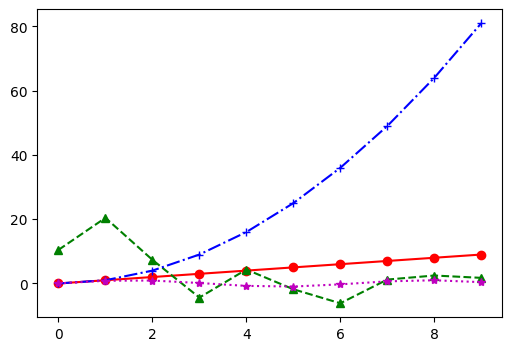

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, 'ro-')
ax.plot(d2, 'g^--')
ax.plot(d3, 'b+-.')
ax.plot(d4, 'm*:')

The above figure could also have been generated explicitly in the following way:

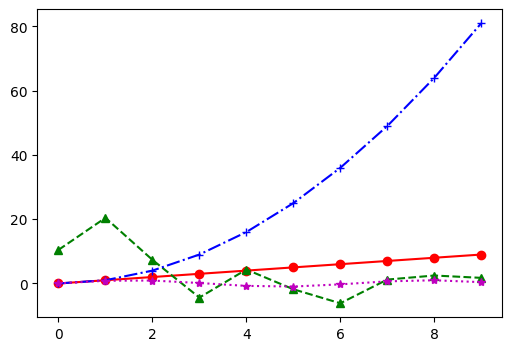

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, color='r', marker='o', linestyle='-')
ax.plot(d2, color='g', marker='^', linestyle='--')
ax.plot(d3, color='b', marker='+', linestyle='-.')
ax.plot(d4, color='m', marker='*', linestyle=':')

[TABLE OF CONTENTS](#contents)

<a id='lesson43'></a>
## 4.3 Setting Limits

Setting the limits of the X-Axis and Y-Axis is accomplished by the `set_xlim()` and `set_ylim()` methods of the `axes` object.  You pass the starting and ending values of the X=Axis or Y-Axis.

(-5.0, 20.0)

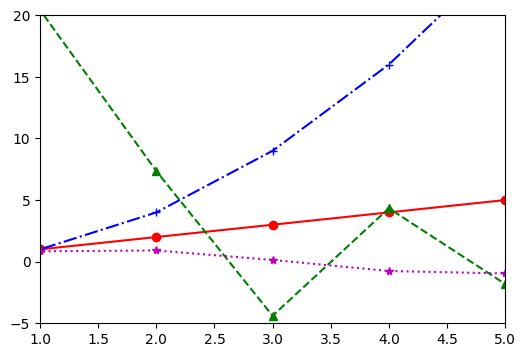

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, 'ro-')
ax.plot(d2, 'g^--')
ax.plot(d3, 'b+-.')
ax.plot(d4, 'm*:')
ax.set_xlim(1, 5)
ax.set_ylim(-5, 20)

If you're using the `set()` method, you have set the keywords `xlim` and `ylim` to a list containing the starting and ending values of the X-Axis or Y-Axis.

[(1.0, 5.0), (-5.0, 20.0)]

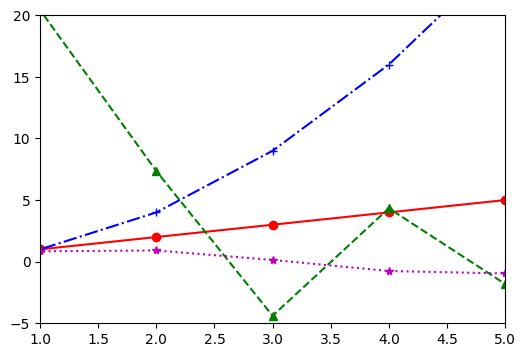

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, 'ro-')
ax.plot(d2, 'g^--')
ax.plot(d3, 'b+-.')
ax.plot(d4, 'm*:')
ax.set(xlim=[1, 5], ylim=[-5, 20])

[TABLE OF CONTENTS](#contents)

<a id='lesson44'></a>
## 4.4 Title, axis labels, ticks and ticklabels

Let's load the Dow Jones data to a DataFrame so that we could plot it:

In [71]:
import pandas as pd
# Dataset download URL
url = "https://raw.githubusercontent.com/RonKG/Machine-Learning-Projects-2/master/1.%20data_cleaning_project/data/Dow%20Jones%20Industrial%20Average%20DJI.csv"

df = pd.read_csv(url,
                  header=0,
                  parse_dates = True,
                  index_col=0)
df.columns = df.columns.str.strip() # clean column labels of whitespaces)

display(df.head())

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1985-01-01,1277.719971,1305.099976,1266.890015,1286.770020,1286.770020,44450000
1985-02-01,1276.939941,1307.530029,1263.910034,1284.010010,1284.010010,207300000
1985-03-01,1285.339966,1309.959961,1242.819946,1266.780029,1266.780029,201050000
1985-04-01,1264.800049,1290.300049,1245.800049,1258.060059,1258.060059,187110000
1985-05-01,1257.180054,1320.790039,1235.530029,1315.410034,1315.410034,242250000


In [72]:
df.to_csv("Datasets/DJIA.csv", index=False)

print("File saved successfully in the Datasets folder.")

File saved successfully in the Datasets folder.


In [73]:
dfD = df.copy()
dfD.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1985-01-01,1277.719971,1305.099976,1266.890015,1286.770020,1286.770020,44450000
1985-02-01,1276.939941,1307.530029,1263.910034,1284.010010,1284.010010,207300000
1985-03-01,1285.339966,1309.959961,1242.819946,1266.780029,1266.780029,201050000
1985-04-01,1264.800049,1290.300049,1245.800049,1258.060059,1258.060059,187110000
1985-05-01,1257.180054,1320.790039,1235.530029,1315.410034,1315.410034,242250000


In [ ]:
dfD['date'] = pd.to_datetime(
    dfD['date'],
    format='%m/%d/%Y'
)

In [74]:
print(dfD.dtypes)

Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


Here's what the default plot would look like

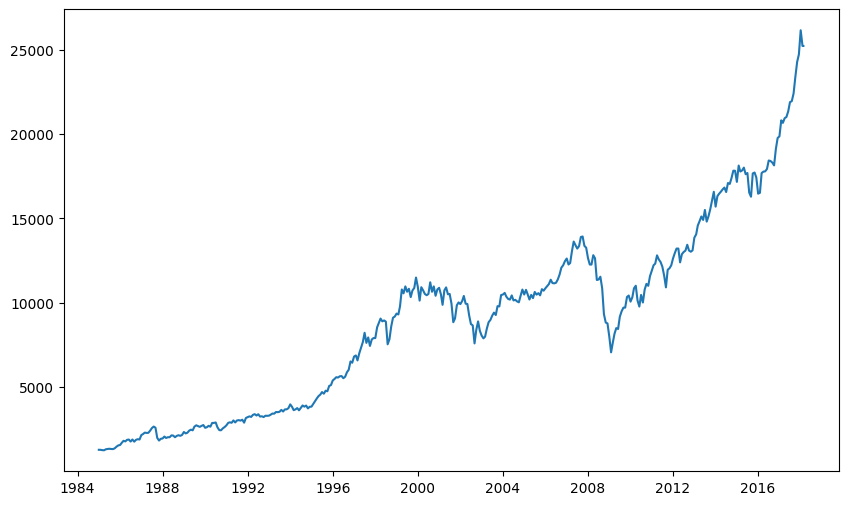

In [76]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(dfD.Close)


Now lets's change some plot setting

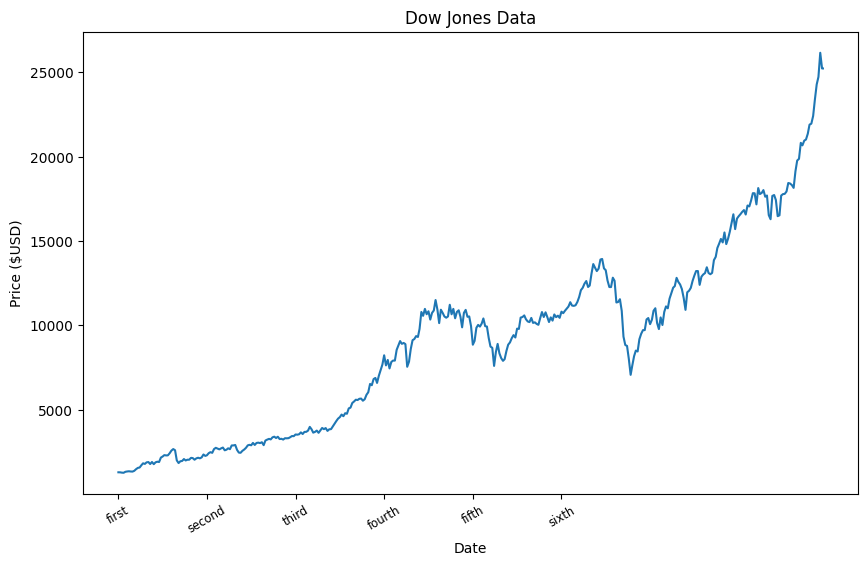

In [77]:
fig, ax = plt.subplots(figsize=(10,6))
ax.set_title("Dow Jones Data")
ax.set_xlabel("Date")
ax.set_ylabel("Price ($USD)")
xticks = [dfD.index[0], dfD.index[50], dfD.index[100], dfD.index[150], dfD.index[200], dfD.index[250]]
ax.set_xticks(xticks)
xlabels = ['first', 'second', 'third', 'fourth', 'fifth', 'sixth']
ax.set_xticklabels(xlabels, rotation=30, fontsize='small')
ax.plot(dfD.Close)

Recall that we could actually use `ax.set()` with keyword arguments for several of the `set` statements above. The only exception is `set_xticklabels()` since we're specifying more parameters for it (`rotation` and `fontsize`).

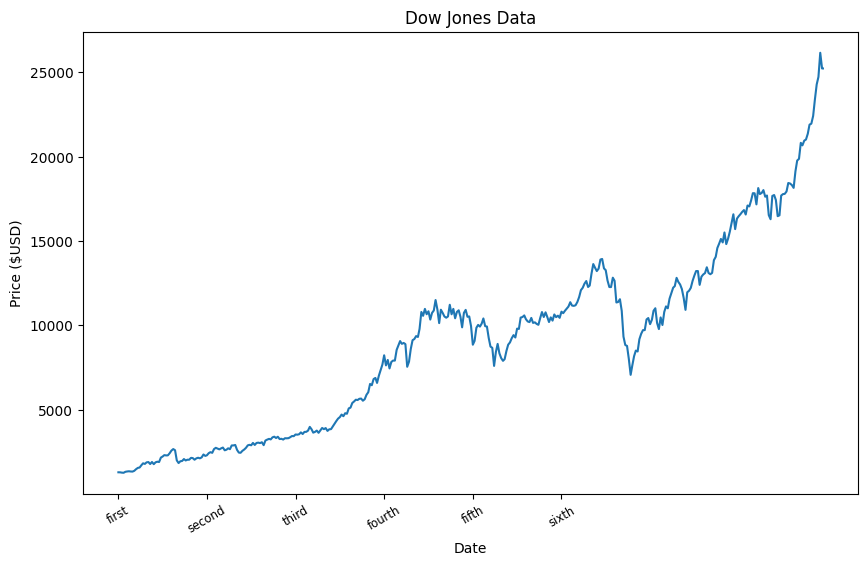

In [78]:
fig, ax = plt.subplots(figsize=(10,6))
ax.set(title="Dow Jones Data",
       xlabel="Date",
       ylabel="Price ($USD)",
       xticks=[dfD.index[0], dfD.index[50], dfD.index[100], dfD.index[150], dfD.index[200], dfD.index[250]])
ax.set_xticklabels(['first', 'second', 'third', 'fourth', 'fifth', 'sixth'],
                   rotation=30,
                   fontsize='small')
ax.plot(dfD.Close)

[TABLE OF CONTENTS](#contents)

<a id='lesson45'></a>
## 4.5 Legends

To add legends to plots, pass a `label` keyword argument to the `plot()` function, then call `axes.legend()` or `plt.legend()`

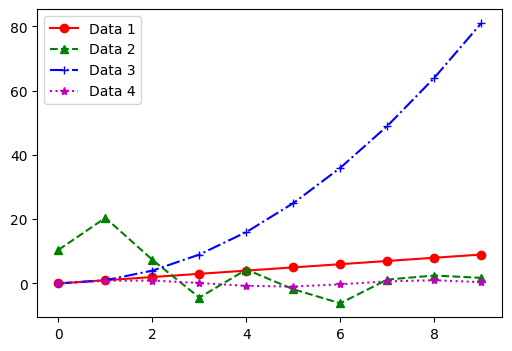

In [79]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, 'ro-', label='Data 1')
ax.plot(d2, 'g^--', label='Data 2' )
ax.plot(d3, 'b+-.', label='Data 3')
ax.plot(d4, 'm*:', label='Data 4')
ax.legend()

You could pass a `loc` argument for `ax.legend()`. Below are the possible values:

#### Legend Location Options
    Location String   Location Code
    ===============   =============
    'best'            0
    'upper right'     1
    'upper left'      2
    'lower left'      3
    'lower right'     4
    'right'           5
    'center left'     6
    'center right'    7
    'lower center'    8
    'upper center'    9
    'center'          10

[TABLE OF CONTENTS](#contents)

<a id='lesson46'></a>
## 4.6 Annotations

The code below is from [PDA]. The data is obtained from Yahoo! Finance.

In [81]:
# Dataset download URL
url = "https://raw.githubusercontent.com/pydata/pydata-book/3rd-edition/examples/spx.csv"

df = pd.read_csv(url)
df.columns = df.columns.str.strip() # clean column labels of whitespaces)

display(df.head())


,Date,SPX
0,1990-02-01 00:00:00,328.79
1,1990-02-02 00:00:00,330.92
2,1990-02-05 00:00:00,331.85
3,1990-02-06 00:00:00,329.66
4,1990-02-07 00:00:00,333.75


In [82]:
df.to_csv("Datasets/spx.csv", index=False)

print("File saved successfully in the Datasets folder.")

File saved successfully in the Datasets folder.


Text(0.5, 1.0, 'Important dates in the 2008-2009 financial crisis')

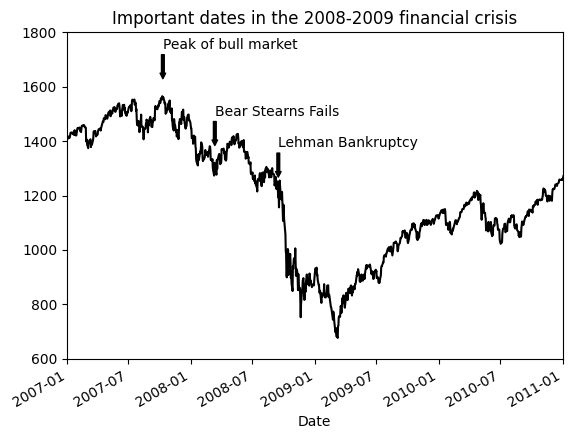

In [83]:
from datetime import datetime

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

data = pd.read_csv('Datasets/spx.csv', index_col=0, parse_dates=True)
spx = data['SPX']

spx.plot(ax=ax, style='k-')

crisis_data = [
    (datetime(2007, 10, 11), 'Peak of bull market'),
    (datetime(2008, 3, 12), 'Bear Stearns Fails'),
    (datetime(2008, 9, 15), 'Lehman Bankruptcy')
]

for date, label in crisis_data:
    ax.annotate(label, xy=(date, spx.asof(date) + 75),
                xytext=(date, spx.asof(date) + 225),
                arrowprops=dict(facecolor='black', headwidth=4, width=2,
                                headlength=4),
                horizontalalignment='left', verticalalignment='top')

# Zoom in on 2007-2010
ax.set_xlim(['1/1/2007', '1/1/2011'])
ax.set_ylim([600, 1800])

ax.set_title('Important dates in the 2008-2009 financial crisis')

#PDA

Let's redo the code in a way we're more familiar with:

In [84]:
data = pd.read_csv('Datasets/spx.csv', index_col=0, parse_dates=True)
data.head()

,SPX
Date,
1990-02-01,328.79
1990-02-02,330.92
1990-02-05,331.85
1990-02-06,329.66
1990-02-07,333.75


In [85]:
spx = data['SPX']
spx.head()

,SPX
Date,
1990-02-01,328.79
1990-02-02,330.92
1990-02-05,331.85
1990-02-06,329.66
1990-02-07,333.75


Text(0.5, 1.0, 'Important dates in the 2008-2009 financial crisis')

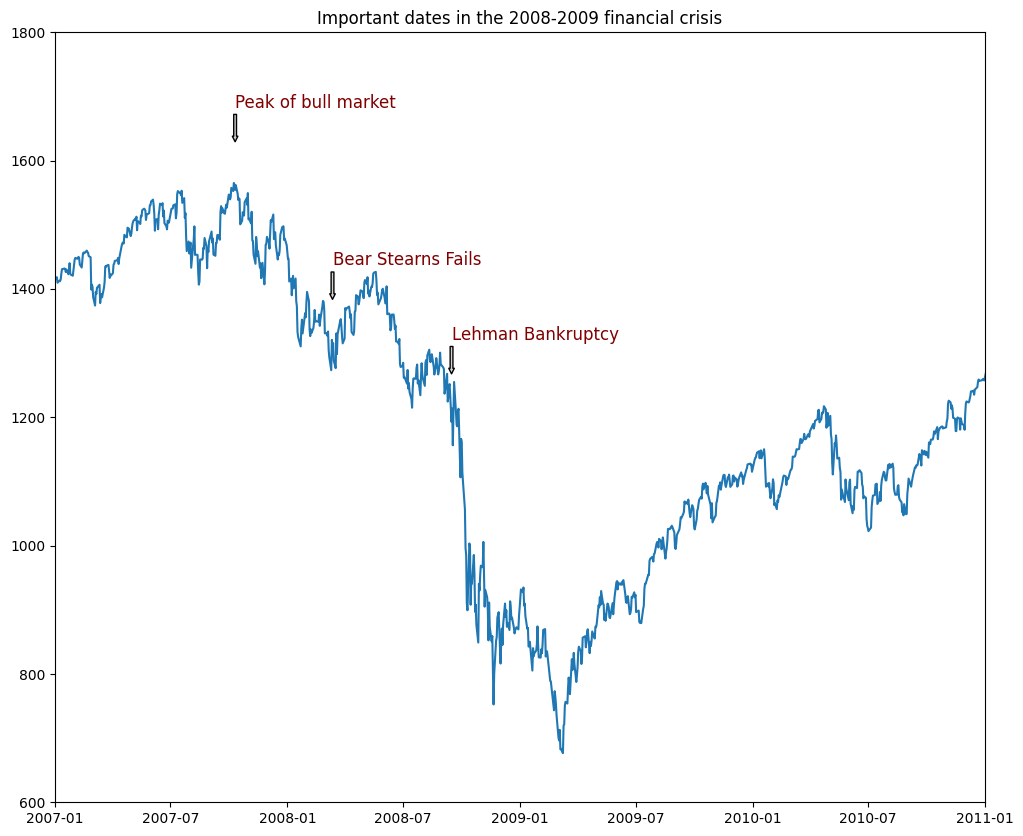

In [90]:
from datetime import datetime

fig, ax = plt.subplots(figsize=(12,10))
ax.plot(spx)

crisis_data = [(datetime(2007, 10, 11), 'Peak of bull market'),
               (datetime(2008, 3, 12), 'Bear Stearns Fails'),
               (datetime(2008, 9, 15), 'Lehman Bankruptcy')]

for date, label in crisis_data:
    ax.annotate(label,
                color='maroon',
                size='large',
                xy=(date, spx[date] + 75),
                xytext=(date, spx[date] + 150),
                arrowprops= dict(facecolor='lightgray', headwidth=4, width=2, headlength=4),
                horizontalalignment='left', verticalalignment='top')

    # Zoom in on 2007-2010
ax.set_xlim([datetime(2007, 1, 1), datetime(2011, 1, 1)])
ax.set_ylim([600, 1800])

ax.set_title('Important dates in the 2008-2009 financial crisis')

#PDA with slight edits from #あ



[TABLE OF CONTENTS](#contents)

<a id='lesson47'></a>
## 4.7 Log Scale and Other Plot Types

### 4.7.1 Log Scale and Scatter Plot

For data that spans several orders of magnitude, visualization could be improved using a logarithmic scale.  You can use `set_xscale()` or `set_yscale` methods of the `axes` object to set the X-Axis or Y-Axis in logarithmic scale, passing the parameter `'log'`.

Let's try this out using scatter plots (which are created using the `scatter()` method of the `axes` object).

In [91]:
np.random.seed(2121)
x = np.random.randint(1, 100, 100) #generate 100 random numbers in the range [50, 90)
x[:10]

array([97, 77, 80, 12, 41,  8, 59, 35, 16, 49])

Let's generate data that spans several order of magnitude

In [92]:
base = np.random.rand(100)
powers =  np.random.randint(2, 10, 100)
y = base*(10**powers)

base[:3], powers[:3], y[:3]

(array([0.38705482, 0.46428704, 0.60930654]),
 array([2, 9, 5]),
 array([3.87054825e+01, 4.64287040e+08, 6.09306536e+04]))

Now let's visualize using scatter plot

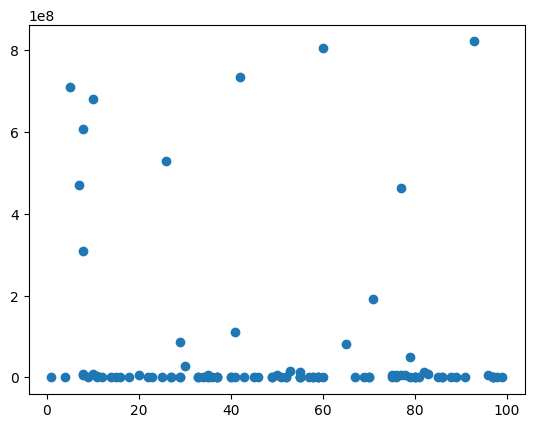

In [93]:
fig, ax = plt.subplots()
ax.scatter(x, y)

Notice that most data are crammed close to the 0 X-Axis value. We can produce a better visualization by setting the Y-Axis in logarithmic scale.

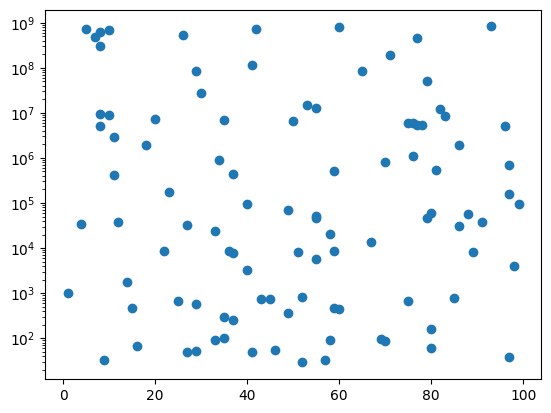

In [94]:
fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_yscale('log')

#### Setting Color, Size & Transparency

To make the plot interesting, we can assign colors, sizes and transparency values (alpha) to our scatter plot.

In [95]:
color_vals = np.random.randint(1, 5, 100)
size_vals = np.random.randint(50, 400, 100)
df = pd.DataFrame({'x':x,
                   'y':y,
                   'color': color_vals,
                   'size': size_vals})
df.head()

,x,y,color,size
0,97,3.870548e+01,3,234
1,77,4.642870e+08,3,278
2,80,6.093065e+04,4,203
3,12,3.820715e+04,2,209
4,41,4.847593e+01,2,232


In [96]:
color_dict = {1:'yellow', 2:'orange', 3:'red', 4:'maroon'}
df['color'] = df.color.apply(lambda x: color_dict[x])

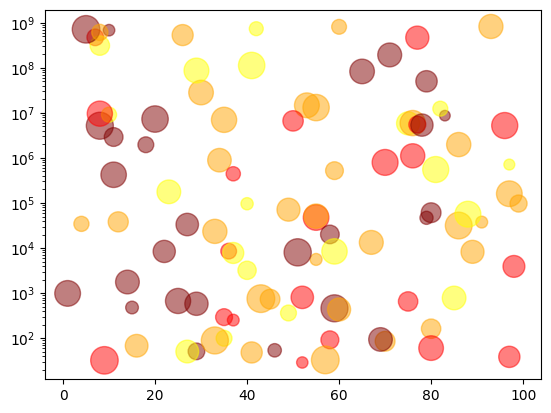

In [97]:
fig, ax = plt.subplots()
ax.scatter(df.x, df.y, alpha=0.5, color= df.color, s=df['size'])
ax.set_yscale('log')

Note: we can't use `df.size` to access the `size` column of the DataFrame since `size` is a property of DataFrame.

### 4.7.2 Bar Chart

Bar charts are created using the `bar()` and `barh()`methods of the `axes` object.

<BarContainer object of 4 artists>

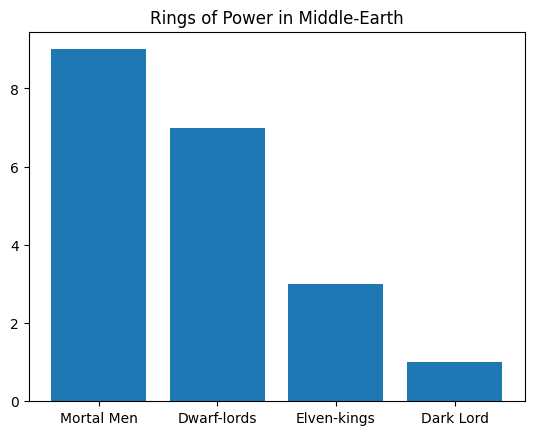

In [98]:
owner = ['Mortal Men','Dwarf-lords','Elven-kings','Dark Lord']
rings = [9, 7, 3, 1]
fig, ax = plt.subplots()
ax.set_title('Rings of Power in Middle-Earth')
ax.bar(owner, rings)

<BarContainer object of 4 artists>

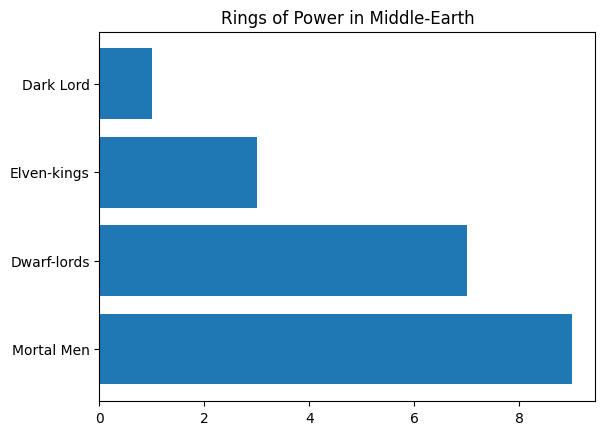

In [99]:
fig, ax = plt.subplots()
ax.set_title('Rings of Power in Middle-Earth')
ax.barh(owner, rings)

### 4.7.3 Histogram

To create a histogram, call `plt.hist()` in an axes object. You can pass a `bins` argument that controls the number of bins into which the data will be segregated.

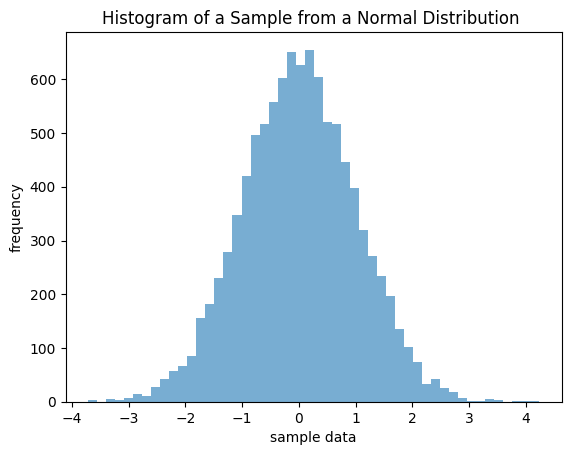

In [100]:
# get 10000 numbers from a normal distribution with mean=0 and stdev=1
sample_data = np.random.normal(0, 1, 10000)
fig, ax = plt.subplots()
ax.set_ylabel('frequency')
ax.set_xlabel('sample data')
ax.set_title('Histogram of a Sample from a Normal Distribution ')
plt.hist(sample_data, bins=50, alpha=0.6);

[TABLE OF CONTENTS](#contents)

<a id='lesson48'></a>
## 4.8 Saving Plots

Saving plots is accomplished by the `plt.savefig` command.

**Call signature**
```python
savefig(fname, dpi=None, facecolor='w', edgecolor='w',
      orientation='portrait', papertype=None, format=None,
      transparent=False, bbox_inches=None, pad_inches=0.1,
      frameon=None)
```

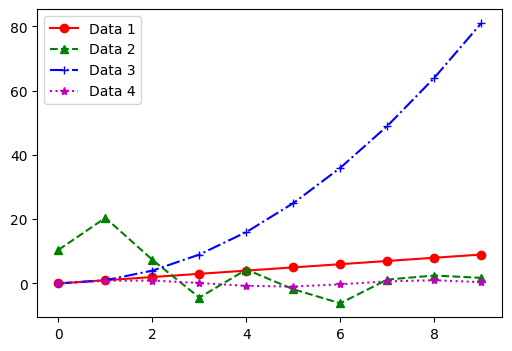

In [101]:
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(d1, 'ro-', label='Data 1')
ax.plot(d2, 'g^--', label='Data 2' )
ax.plot(d3, 'b+-.', label='Data 3')
ax.plot(d4, 'm*:', label='Data 4')
ax.legend()

plt.savefig('sample_plot.jpg')
plt.savefig('sample_plot.png', transparent=True)
plt.savefig('sample_plot.svg')
plt.savefig('sample_plot.pdf')

In [102]:
!dir sample*

sample_plot.jpg  sample_plot.pdf  sample_plot.png  sample_plot.svg


[TABLE OF CONTENTS](#contents)

<a id='lesson5'></a>
# 5. Commands-Style Plotting with `pyplot`

## 5.1 Introduction

*Several portions of this section come from [MPT]. Text directly lifted from this source are indented in a quote block, while code are annotated with a `#MPT` at the last line of the code cell.*


From Lesson 4, recall that
> There are two ways of plotting in `matplotlib`. The first uses `matplotlib` objects in an Object Oriented Programming (OOP) fashion. The second uses command-style functions.  The first method is more explicit and flexible and could thus be more laborious. The second is shorter (and many times cleaner). However, it is less flexible and may not be able to handle more detailed plotting needs.

[あ]

In this section, we will look at this second method of plotting.

> The `pyplot` module of `matplotlib` is a collection of **command-style functions** that makes `matplotlib` work like `MATLAB`.
>
> Each ``pyplot`` function makes some change to a `figure`: e.g., creates a figure, creates a plotting area
in a figure, plots some lines in a plotting area, decorates the plot with labels, etc.
>
> In `pyplot` various states are preserved across function calls, such that:
> - `pyplot`  keeps track of things like the current `figure` and plotting area
> - the plotting functions are directed to the current `axes`
>
> (Please note that `axes` here
and in most places in the documentation refers to the `axes`
[part of a figure ](http://matplotlib.org/faq/usage_faq.html#parts-of-a-figure)
and ***not*** *the strict mathematical term for more than one* ***axis***).

[MPT]

## 5.2 Figures and Subplots

### Current figure and current axes

>`pyplot`, like `MATLAB`, has the concept of the **current `figure`** and the **current `axes`**.  *All plotting commands apply to the current `axes`*.  
>
>Thus, when using `pyplot`, you don't have to worry about the current `figure` and current `axes`, because they are taken care of behind the scenes.

[MPT]

The fact that `pyplot` keeps track of the current `figure` and current `axes` makes it cleaner, but at the same time, makes it less explicit. For example, you can immediately create a plot with the following code:

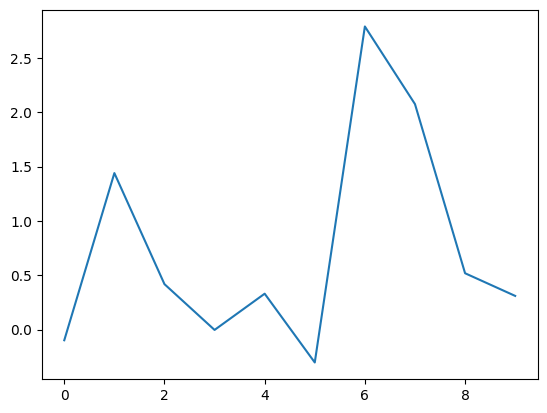

In [103]:
plt.plot(np.random.randn(10));

What happens is that at the background, matplotlib has already created a `figure` with one `axes` in it, and has proceeded with carrying out your plotting command.

If want to explicitly get the current `figure` or `axes`, you could use the following `pyplot` commands:
- `plt.gca()`  returns the
current axes (an `Axes` instance or object)
- `plt.gcf()` returns the current figure(a `Figure` instance or object).

You can clear the current figure with `plt.clf()`
and the current axes with `plt.cla()`.  

The code below shows how to get the `figure` and `axes` objects that `pyplot` has automatically created after the call to `plt.plot()`.  We can then proceed to use them to customize some features of the plot.

Text(0.5, 1.0, 'New Title')

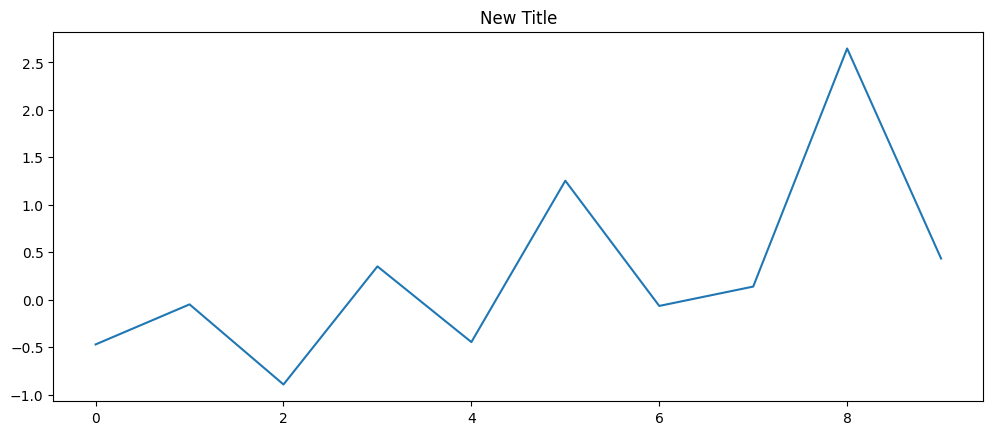

In [104]:
plt.plot(np.random.randn(10))
fig = plt.gcf()
ax = plt.gca()
fig.set_figwidth(12,8)
ax.set_title('New Title')

### Working with Subplots or Multiple axes

To explicitly create a figure (e.g. in order to pass some arguments), a call to `plt.figure()` could be done.

To create multiple `axes` or `subplots`, you simply call `plt.subplot()` (notice that this is different from `plt.subplots` which has an `'s'` at the end) and pass 3 parameters, `nrow`, `ncol` and `index`. `Index` start at 1 from the top corner, then goes to the left, then down.

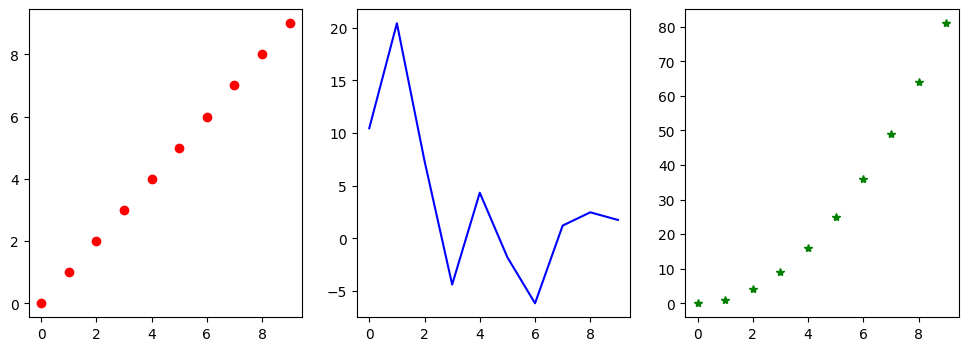

In [105]:
fig = plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.plot(d1, 'ro') #plot with red circle markers

plt.subplot(1,3,2)
plt.plot(d2, 'b-') #plot with blue line

plt.subplot(1,3,3)
plt.plot(d3, 'g*') #plot with green star markers

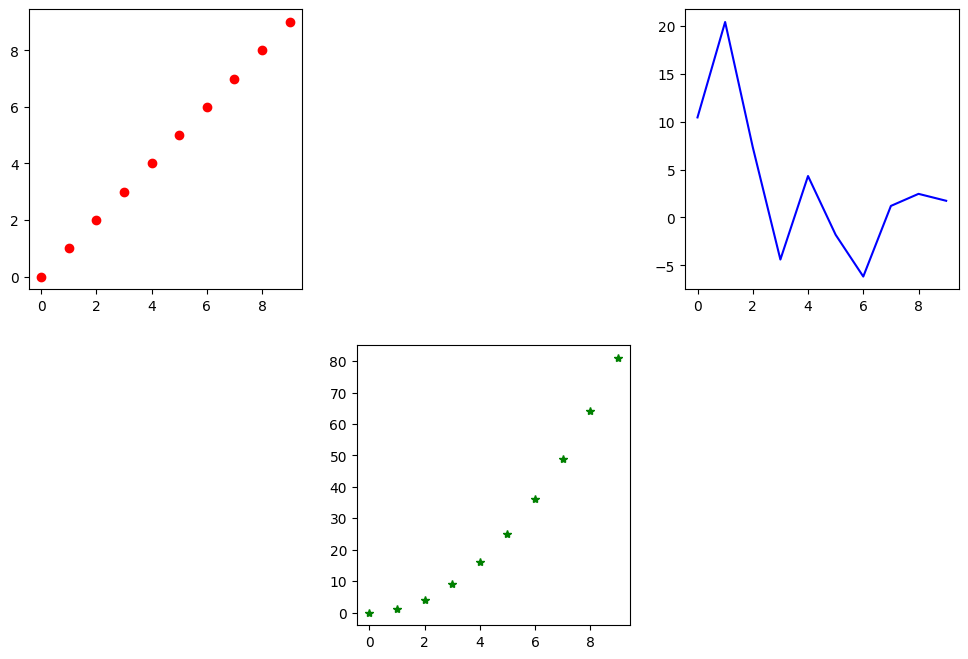

In [106]:
fig = plt.figure(figsize=(12,8))

plt.subplot(2,3,1)
plt.plot(d1, 'ro') #plot with red circle markers

plt.subplot(2,3,3)
plt.plot(d2, 'b-') #plot with blue line

plt.subplot(2,3,5)
plt.plot(d3, 'g*') #plot with green star markers

## 5.3  Commands-Style and OOP-Style plotting

There is a correspondence between `pyplot`'s Commands-Style functions and OOP-Style plotting. Most of the object methods that start with  `set_` or `get_` have a corresponding Commands-Style function. Observe the next two code cells, which do the same thing. The first uses OOP-Style, while the second uses Commands-Sytle

### Plotting with OOP-Style

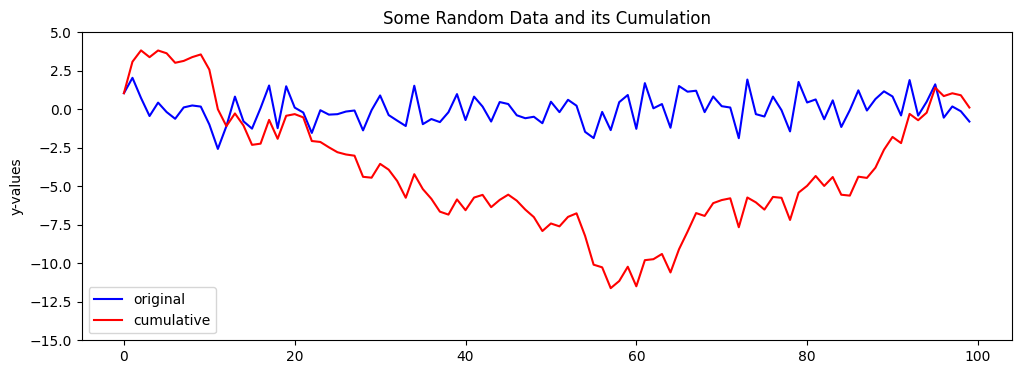

In [107]:
np.random.seed(2121)
data = np.random.randn(100)
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(data, 'b-', label='original')
ax.plot(data.cumsum(), 'r-', label='cumulative')
ax.set_title('Some Random Data and its Cumulation')
ax.set_ylabel('y-values')
ax.set_ylim(-15, 5)
ax.legend()

In [108]:
plt.xticks?

### Plotting with Commands-Style

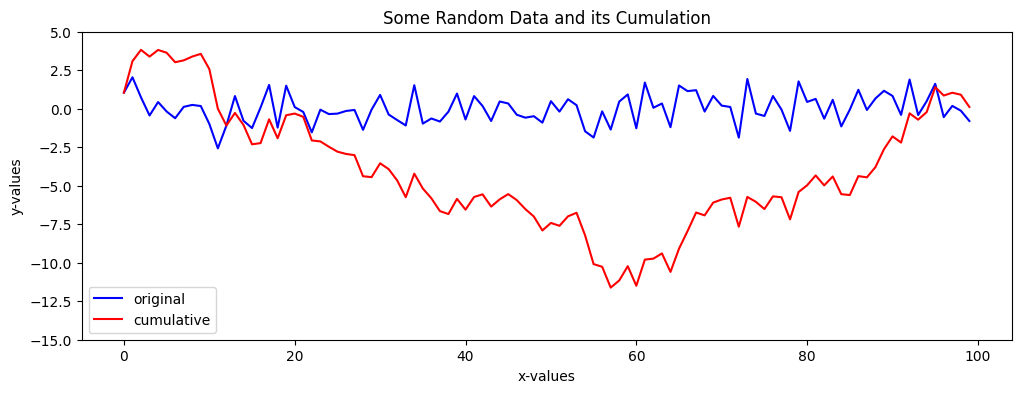

In [109]:
np.random.seed(2121)
data = np.random.randn(100)
fig = plt.figure(figsize=(12,4))
plt.plot(data, 'b-', label='original')
plt.plot(data.cumsum(), 'r-', label='cumulative')
plt.title('Some Random Data and its Cumulation')
plt.xlabel('x-values')
plt.ylabel('y-values')
plt.ylim(-15, 5)
plt.legend()

### Which Style Should You Use?

For simple plots which don't require customization, the Commands-Style is definitely simpler and faster to write. However,
it is advisable to be familiar with the OOP-Style of plotting since it is more explicit and more flexible. As you grow in mastery over customizing plots, then you can easily combine OOP-Style with Commands-Style plotting, shifting from one to another depending on whether you are aiming for simplicity or flexibility in portions of your code. This is illustrated in the code below lifted from [SLP].

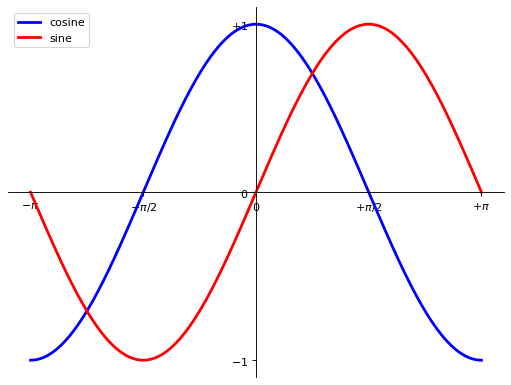

In [110]:
plt.figure(figsize=(8, 6), dpi=80)

# Create a new subplot from a grid of 1x1
plt.subplot(1, 1, 1)

X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)

plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cosine")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-", label="sine")

plt.legend(loc='upper left')

plt.xlim(X.min() * 1.1, X.max() * 1.1)
plt.ylim(C.min() * 1.1, C.max() * 1.1)

plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
          [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$+\pi/2$', r'$+\pi$'])

plt.yticks([-1, 0, +1],
           [r'$-1$', r'$0$', r'$+1$'])

# -------------------------------------------------------------------------
#あ portion where OOP-style is used to move the position of the Axis spines

ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.xaxis.set_ticks_position('bottom')
ax.spines['bottom'].set_position(('data',0))
ax.yaxis.set_ticks_position('left')
ax.spines['left'].set_position(('data',0))
# -------------------------------------------------------------------------

#[SPL]

[TABLE OF CONTENTS](#contents)

<a id='lesson6'></a>
# 6. Plotting with Pandas and Seaborn

## 6.1 Series and DataFrame `plot()` method

Series and DataFrame both have a `plot()` method. Most of the parameters present in `plt.plot()` method are also present in `Series.plot()` and `DataFrame.plot()` methods. You can specify the type of plot by passing a `kind` argument, the default value of which is `'line'`.

<Axes: >

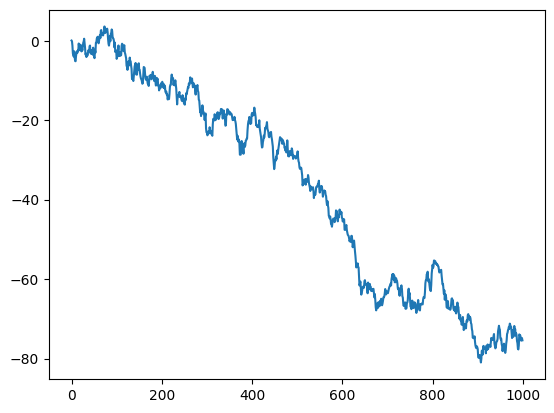

In [111]:
s = pd.Series(np.random.randn(1000).cumsum())
s.plot()

In [112]:
help(s.plot)

Help on PlotAccessor in module pandas.plotting._core object:

class PlotAccessor(pandas.core.base.PandasObject)
 |  PlotAccessor(data: 'Series | DataFrame') -> 'None'
 |
 |  Make plots of Series or DataFrame.
 |
 |  Uses the backend specified by the
 |  option ``plotting.backend``. By default, matplotlib is used.
 |
 |  Parameters
 |  ----------
 |  data : Series or DataFrame
 |      The object for which the method is called.
 |  x : label or position, default None
 |      Only used if data is a DataFrame.
 |  y : label, position or list of label, positions, default None
 |      Allows plotting of one column versus another. Only used if data is a
 |      DataFrame.
 |  kind : str
 |      The kind of plot to produce:
 |
 |      - 'line' : line plot (default)
 |      - 'bar' : vertical bar plot
 |      - 'barh' : horizontal bar plot
 |      - 'hist' : histogram
 |      - 'box' : boxplot
 |      - 'kde' : Kernel Density Estimation plot
 |      - 'density' : same as 'kde'
 |      - 'area' 

#### Possible values for the `kind` parameter
    
    - 'line' : line plot (default)
    - 'bar' : vertical bar plot
    - 'barh' : horizontal bar plot
    - 'hist' : histogram
    - 'box' : boxplot
    - 'kde' : Kernel Density Estimation plot
    - 'density' : same as 'kde'
    - 'area' : area plot
    - 'pie' : pie plot

#### Histogram

<Axes: ylabel='Frequency'>

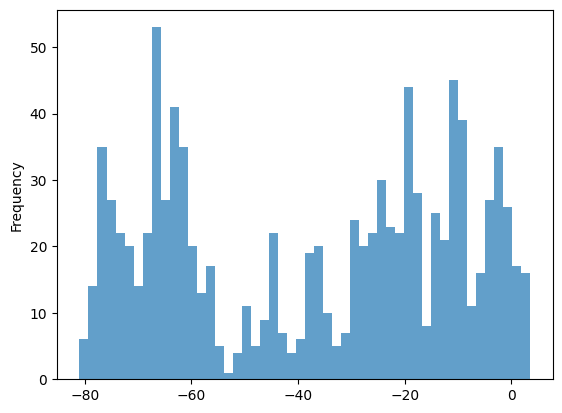

In [113]:
s.plot(kind='hist', bins=50, alpha=0.7)

<Axes: >

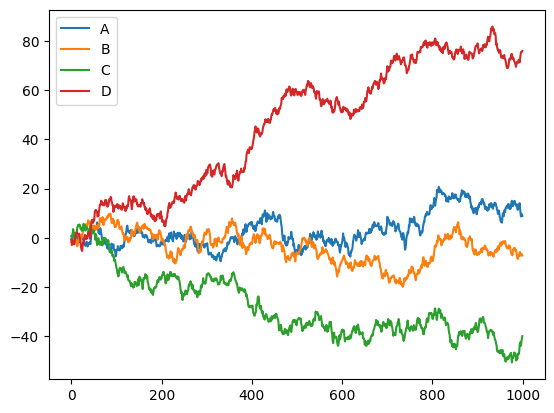

In [114]:
df = pd.DataFrame(np.random.randn(1000,4),
                  index=np.arange(1000),
                  columns=list('ABCD'))
df = df.cumsum()
df.plot()

#### Boxplot

<Axes: >

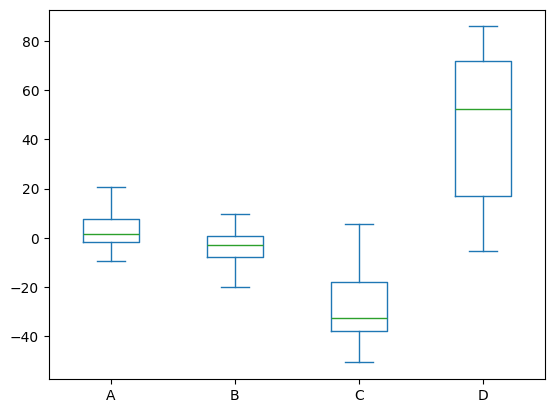

In [115]:
df.plot(kind='box')

#### Bar Chart

In [116]:
df = pd.DataFrame({'A': np.random.randint(1,10,1000),
                   'B': np.random.randint(8,20,1000),
                   'C': np.random.randint(18,30,1000),
                   'D': np.random.randint(28,40,1000)})
df.tail()

,A,B,C,D
995,4,11,28,35
996,8,8,25,28
997,9,17,23,34
998,1,15,24,37
999,5,12,24,36


In [117]:
#PDA
df = pd.DataFrame(np.random.rand(6, 4),
                  index=['one', 'two', 'three', 'four', 'five', 'six'],
                  columns=pd.Index(['A', 'B', 'C', 'D'], name='Genus'))
df

Genus,A,B,C,D
one,0.125990,0.846537,0.632412,0.860758
two,0.293499,0.323579,0.712387,0.026957
three,0.887876,0.407101,0.195894,0.199430
four,0.359356,0.185565,0.565263,0.097006
five,0.508516,0.020306,0.590554,0.717654
six,0.821893,0.412277,0.038591,0.859082


<Axes: >

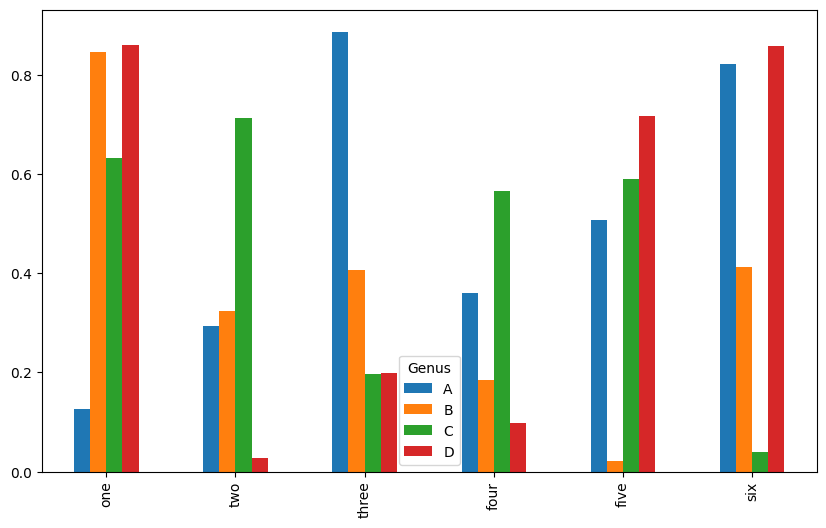

In [118]:
df.plot.bar(figsize=(10,6))

#### Stacked Bar Chart

<Axes: >

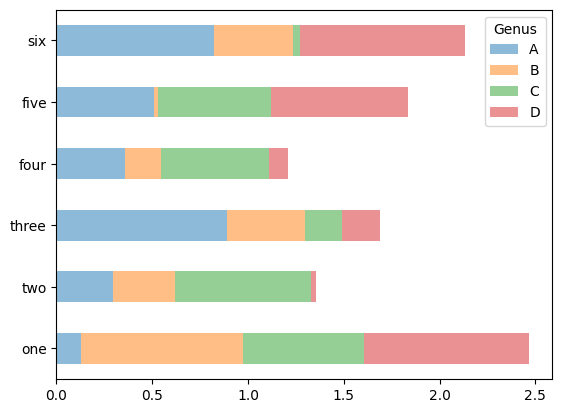

In [119]:
df.plot.barh(stacked=True, alpha=0.5)

## 6.2 Seaborn

Another popular visualization tool for python is `seaborn`. `Seaborn`  creates aesthetically appealing plots and adds other plot methods that are useful for exploratory data analysis.  You can install `seaborn` in `Anaconda` by typing `conda install seaborn` at the terminal.

Below are 2 examples of visualizations with `seaborn`.

In [122]:
df_hprice = pd.read_csv(r'Datasets/hprice1_ex8-4.csv')
df_hprice.head()

,price,lotsize,sqrft,bdrms
0,300.0,6126,2438,4
1,370.0,9903,2076,3
2,191.0,5200,1374,3
3,195.0,4600,1448,3
4,373.0,6095,2514,4


#### `sns.regplot`

Plots a linear regression line

<Axes: xlabel='price', ylabel='sqrft'>

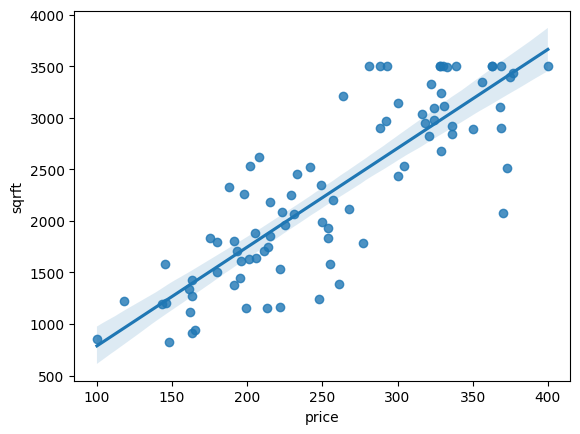

In [126]:
import seaborn as sns
sns.regplot(x='price', y='sqrft', data=df_hprice)

#### `sns.pairplot()`
Analyzes pairs columns of datasets

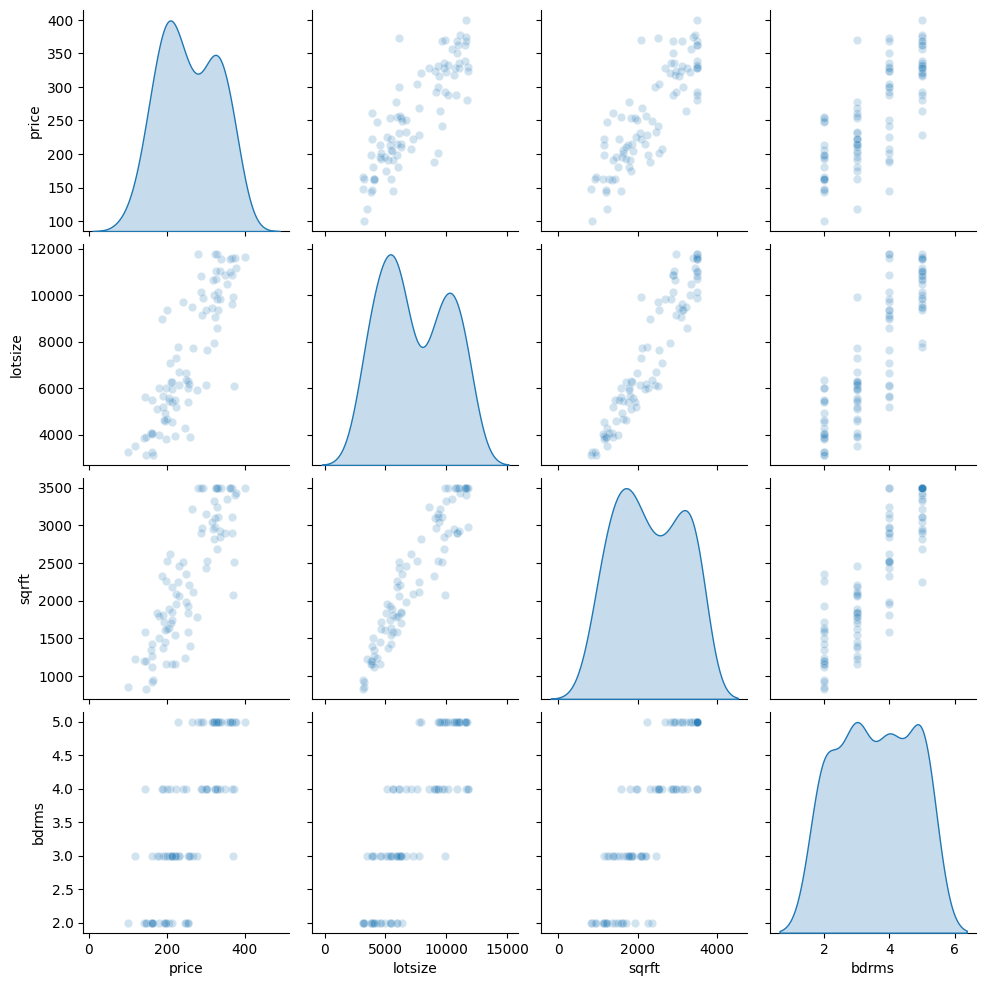

In [128]:
sns.pairplot(df_hprice, diag_kind='kde', plot_kws={'alpha': 0.2})

[TABLE OF CONTENTS](#contents)

<a id='lesson7'></a>
# 7. References

Aside from the references mentioned in the Credits portion of this tutorial, it is highly advisable to checkout the official documentation of `matplotlib` at  [matplotlib.org](http://matplotlib.org).  That site contains
- [Gallery](http://matplotlib.org/gallery.html)
- [Examples](http://matplotlib.org/examples/index.html)
- [FAQs](http://matplotlib.org/faq/index.html)
- [API documentation](http://matplotlib.org/api/index.html)


[TABLE OF CONTENTS](#contents)